IMPORT MY PROJECT LIBRARIES

In [3]:
import pandas as pd 
import numpy as np

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

CREATE MY AI TRAINING DATASET

In [4]:
df = pd.read_csv("Sms_spam_collection.csv")
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
print("Dataset size:", df.shape)

print(df.head())

print(df["label"].value_counts())

Dataset size: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64


DATA CLEANING MY MODEL

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate messages:")
print(df.duplicated().sum())

df = df.dropna()

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)

df.head()

Missing values:
label      0
message    0
dtype: int64

Duplicate messages:
403

Cleaned dataset shape: (5169, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


STANDARDIZE AND CHECK MESSAGE DISTRIBUTION

In [8]:
df.columns = df.columns.str.strip().str.lower()

df["label"] = df["label"].str.strip().str.lower()

label_counts = df["label"].value_counts()

print("Message Distribution")
print(label_counts)

Message Distribution
label
ham     4516
spam     653
Name: count, dtype: int64


SEPARATE FEATURES AND TARGET FOR MY MODEL

In [9]:
X = df["message"]
y = df["label"]

print("Total message:", len(X))
print("Total label:", len(y))

print("\nSample messages:")
print(X.head())

Total message: 5169
Total label: 5169

Sample messages:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: str


SPLIT MY DATASET INTO TRAINING AND TESTING DATA


In [10]:
X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set size:", len(X_train))
print("Test set size:", len(X_test))

Training set size: 4135
Test set size: 1034


TEXT VECTORIZATION USING TF-IDF

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

# Transform training messages
X_train_tfidf = vectorizer.fit_transform(X_train)

# Transform testing messages
X_test_tfidf = vectorizer.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4135, 5000)
Testing data shape: (1034, 5000)


TRAINING MY AI MODEL

In [32]:
from sklearn.naive_bayes import MultinomialNB

In [33]:
model = MultinomialNB()

In [40]:
from sklearn.naive_bayes import MultinomialNB

# Create a fresh model
spam_model = MultinomialNB()

# Train using the current TF-IDF training data
spam_model.fit(X_train_tfidf, y_train)

# Check feature compatibility
print("Vectorizer features:", X_train_tfidf.shape[1])
print("Model features:", spam_model.n_features_in_)

print("\nNew model trained successfully!")

Vectorizer features: 5000
Model features: 5000

New model trained successfully!


In [41]:
model.fit(X_train_vectorizer, y_train)
print("Model training completed successfully")

Model training completed successfully


MAKING PREDICTION IN OUR AI MODEL

In [43]:
y_pred = model.predict(X_test_vectorizer)

print("Ai predictions")
print(y_pred)

Ai predictions
['ham' 'ham' 'ham' ... 'spam' 'ham' 'ham']


EVALUATE MY AI MODEL

In [44]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [45]:
Accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", Accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred))

Model Accuracy: 95.26112185686654 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.77       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.96      0.95      0.95      1034


Confusion Matrix:
[[903   0]
 [ 49  82]]


In [47]:
test_messages = [
    "Congratulations! You have won a free iPhone. Click here to claim.",
    "Hey, how are you doing today?",
    "URGENT! Your account has been selected for a cash prize.",
    "Are we still meeting tomorrow?",
    "You have won a free ticket. Call now!"
]

# Convert messages into TF-IDF features
test_vectors = vectorizer.transform(test_messages)

# Predict messages
predictions = spam_model.predict(test_vectors)

# Display results
for message, prediction in zip(test_messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("-" * 50)

Message: Congratulations! You have won a free iPhone. Click here to claim.
Prediction: SPAM
--------------------------------------------------
Message: Hey, how are you doing today?
Prediction: HAM
--------------------------------------------------
Message: URGENT! Your account has been selected for a cash prize.
Prediction: SPAM
--------------------------------------------------
Message: Are we still meeting tomorrow?
Prediction: HAM
--------------------------------------------------
Message: You have won a free ticket. Call now!
Prediction: HAM
--------------------------------------------------


In [50]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict using the new model
y_pred_new = spam_model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred_new)

print("New Model Accuracy:", accuracy * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_new))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_new))

New Model Accuracy: 96.90522243713733 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       903
        spam       1.00      0.76      0.86       131

    accuracy                           0.97      1034
   macro avg       0.98      0.88      0.92      1034
weighted avg       0.97      0.97      0.97      1034


Confusion Matrix:
[[903   0]
 [ 32  99]]


SAVED MY TRAINED MODEL

In [51]:

import joblib

# Save the trained model
joblib.dump(spam_model, "spam_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [53]:
# Save the TF-IDF vectorizer

joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!


CONFUSION MATRIX

TESTING MY MODEL WITH MY OWN MESSAGE

In [55]:
new_message = ["Congratulation! you have won  free cash, claim your prize now by clicking on the link below!!"]

new_message_vectorized = vectorizer.transform(new_message)

prediction =spam_model.predict(new_message_vectorized)

print("Message:", new_message[0])
print("Ai Prediction:", prediction[0])

Message: Congratulation! you have won  free cash, claim your prize now by clicking on the link below!!
Ai Prediction: spam


In [56]:
new_message = ["Hello, how are you?.. i just wanted to check in and see how you are doing. Hope everything is going well for you. Let's catch up soon!"]

new_message_vectorized = vectorizer.transform(new_message)

prediction = spam_model.predict(new_message_vectorized)

print("Message:", new_message[0])
print("Ai Prediction:", prediction[0])

Message: Hello, how are you?.. i just wanted to check in and see how you are doing. Hope everything is going well for you. Let's catch up soon!
Ai Prediction: ham


In [57]:
new_message = ["Congratulations! you have won a free car, claim your prize now by clicking on the link below!!"]

new_message_vectorized = vectorizer.transform(new_message)

prediction = spam_model.predict(new_message_vectorized)

print("Message:", new_message[0])
print("Ai Prediction:", prediction[0])

Message: Congratulations! you have won a free car, claim your prize now by clicking on the link below!!
Ai Prediction: spam


In [58]:
new_message = ["Hello, i am on my way to the office, will be there in 10 minutes"]

new_message_vectorized = vectorizer.transform(new_message)

prediction = spam_model.predict(new_message_vectorized)

print("Message:", new_message[0])
print("Ai Prediction:", prediction[0])

Message: Hello, i am on my way to the office, will be there in 10 minutes
Ai Prediction: ham


BUILD A REUSABLE SPAM DETECTOR

In [59]:
def check_message(message):
    new_message_vectorized = vectorizer.transform([message])
    prediction = spam_model.predict(new_message_vectorized)
    
    print("Message:", message)
    print("Ai Prediction:", prediction[0])
    
check_message("You have won a free trip to Paris! Click here to claim your prize now!")    

Message: You have won a free trip to Paris! Click here to claim your prize now!
Ai Prediction: spam


In [60]:
def check_message(message):
    new_message_vectorized = vectorizer.transform([message])
    prediction =spam_model.predict(new_message_vectorized)
    
    print("Message:", message)
    print("Ai Prediction:", prediction[0])
    
check_message("Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!")

Message: Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!
Ai Prediction: ham


MAKE YOUR AI SPAM DETECTOR INTERACTIVE

In [61]:
while True:
    message = input("Enter a message to check if it's spam or not (or type 'exit' to quit): ")
    if message.lower() == 'exit':
        print("Thank you for using the Ai spam detector. Goodbye!")
        break
    check_message(message)
    print("__________________")

Message: hello what your name
Ai Prediction: ham
__________________
Thank you for using the Ai spam detector. Goodbye!


IMPROVE MY AI MODDEL

In [62]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.77       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.96      0.95      0.95      1034



SAVE MY TRAINED AI MODEL

In [ ]:
import joblib

TEST MY AI LOADED MODEL

In [65]:
import ipywidgets as widgets

CONNECT MY INTERFACE TO MY AI MODEL

In [66]:
import ipywidgets as widgets
from IPython.display import display, clear_output


message_input = widgets.Textarea(
    placeholder="Type your message here...",
    description="Message:",
    layout=widgets.Layout(width="500px", height="100px")
)

check_button = widgets.Button(
    description="Check Message",
    button_style="success"
)


output = widgets.Output()


def check_button_clicked(b):
    with output:
        clear_output(wait=True)

        message = message_input.value.strip()

        if message:
            message_vectorized = loaded_vectorizer.transform([message])
            prediction = loaded_model.predict(message_vectorized)

            print("Your Message:", message)
            print("AI Prediction:", prediction[0])
        else:
            print("Please enter a message!")


check_button.on_click(check_button_clicked)


display(message_input, check_button, output)

Textarea(value='', description='Message:', layout=Layout(height='100px', width='500px'), placeholder='Type you…

Button(button_style='success', description='Check Message', style=ButtonStyle())

Output()

ADDING PREDICTION CONFIDENCE

In [68]:
loaded_model = joblib.load("spam_model.pkl")

loaded_vectorizer = joblib.load("tfidf_vectorizer.pkl")

print("Model and vectorizer loaded successfully!")

Model and vectorizer loaded successfully!


In [69]:
message = ["Congratulations! you have won a free iphone and a wrist watch."]
message_vectorized = loaded_vectorizer.transform(message)
prediction = loaded_model.predict(message_vectorized)
probability = loaded_model.predict_proba(message_vectorized)
print("Prediction:", prediction[0])
print("Confidence:", round(max(probability[0]) * 100, 2), "%")

Prediction: ham
Confidence: 69.16 %


In [70]:
message = ["Hello! how are you doing? hope you had a wonderful sleep."]
message_vectorized = loaded_vectorizer.transform(message)
prediction = loaded_model.predict(message_vectorized)
probability = loaded_model.predict_proba(message_vectorized)
print("Prediction:", prediction[0])
print("Confidence:", round(max(probability[0]) * 100, 2), "%")

Prediction: ham
Confidence: 99.68 %


BUILD A SMARTER MESSAGE TESTER FOR MY MODEL

In [71]:
def detect_spam(message):
    
    message_vectorized = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vectorized)
    probability = loaded_model.predict_proba(message_vectorized)
    
    confidence = max(probability[0]) * 100
    
    print("Message:", message)
    print("Prediction:", prediction[0])
    print("Confidence:", round(confidence, 2), "%")
    
detect_spam("Congratulations! you have won a free iphone and a wrist watch.")    

Message: Congratulations! you have won a free iphone and a wrist watch.
Prediction: ham
Confidence: 69.16 %


In [72]:
def detect_spam(message):
    
    message_vectorized = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vectorized)
    probability = loaded_model.predict_proba(message_vectorized)
    
    confidence = max(probability[0]) * 100
    
    print("Message:", message)
    print("Prediction:", prediction[0])
    print("Confidence:", round(confidence, 2), "%")
    
detect_spam("Hello! how are you doing? hope you had a wonderful sleep.")

Message: Hello! how are you doing? hope you had a wonderful sleep.
Prediction: ham
Confidence: 99.68 %


ALLOW USER TO ENTER THEIR OWN MESSAGE

In [73]:
user_input = input("Enter a message to check if it's spam or not: ")
detect_spam(user_input)

Message: exit
Prediction: ham
Confidence: 87.38 %


ALLOW CONTINOUS MESSAGE DETECTION

In [74]:
while True:
    
    user_input = input("Enter a message to check if it's spam or not (or type 'exit' to quit): ")
    if user_input.lower() == 'exit':
        print("Spam detector closed. Thank you for using the Ai spam detector. Goodbye!")
        break
    detect_spam(user_input)
    print("__________________")

Spam detector closed. Thank you for using the Ai spam detector. Goodbye!


IMPROVE MY MODEL USER INTERFACE

In [75]:
def detect_spam(message):
    message_vectorized = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vectorized)
    probability = loaded_model.predict_proba(message_vectorized)
    confidence = max(probability[0]) * 100
    
    print("\n==========SPAM DETECTOR================")
    print("Message:", message)
    
    if prediction[0] == "spam":
        print("Result: SPAM MESSAGE")
        
    else:
        print("Result: NOT SPAM MESSAGE")    
    
    print("Confidence:", round(confidence, 2), "%")
    
    print("========================================\n")

In [76]:
detect_spam("Hello! how are you doing? hope you had a wonderful sleep.")


==========SPAM DETECTOR================
Message: Hello! how are you doing? hope you had a wonderful sleep.
Result: NOT SPAM MESSAGE
Confidence: 99.68 %



In [77]:
detect_spam("Congratulations! you have won a free iphone and a wrist watch.")


==========SPAM DETECTOR================
Message: Congratulations! you have won a free iphone and a wrist watch.
Result: NOT SPAM MESSAGE
Confidence: 69.16 %



ADD ERROR HANDLING TO MY MODEL

In [78]:
def detect_spam(message):
    
    if not message.strip():
        print("Error: Empty message provided. Please enter a valid message.")
        return
    
    message_vectorized = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vectorized)
    probability = loaded_model.predict_proba(message_vectorized)
    confidence = max(probability[0]) * 100
    
    print("\n==========SPAM DETECTOR================")
    print("Message:", message)
    
    if prediction[0] == "spam":
        print("Result: SPAM MESSAGE")
        
    else:
        print("Result: NOT SPAM MESSAGE")    
    
    print("Confidence:", round(confidence, 2), "%")
    
    print("========================================\n")

In [ ]:
detect_spam("")

Error: Empty message provided. Please enter a valid message.


ADD A MESSAGE FEATURE IN MY MODEL HISTORY

In [79]:
message_history =[]
def check_message(message):
    detect_spam(message)
    message_history.append(message)

In [80]:
check_message("Hello! how are you doing? hope you had a wonderful sleep.")



==========SPAM DETECTOR================
Message: Hello! how are you doing? hope you had a wonderful sleep.
Result: NOT SPAM MESSAGE
Confidence: 99.68 %



In [81]:
check_message("Congratulations! you have won a free iphone and a wrist watch.")


==========SPAM DETECTOR================
Message: Congratulations! you have won a free iphone and a wrist watch.
Result: NOT SPAM MESSAGE
Confidence: 69.16 %



In [82]:
check_message("You have won a free trip to Paris! Click here to claim your prize now!")


==========SPAM DETECTOR================
Message: You have won a free trip to Paris! Click here to claim your prize now!
Result: SPAM MESSAGE
Confidence: 85.15 %



In [83]:
check_message("Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!")


==========SPAM DETECTOR================
Message: Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!
Result: NOT SPAM MESSAGE
Confidence: 99.76 %



In [84]:
check_message("Claim your mobile phone now for free by clicking this link")


==========SPAM DETECTOR================
Message: Claim your mobile phone now for free by clicking this link
Result: SPAM MESSAGE
Confidence: 76.46 %



In [85]:
print("Message History:")
for message in message_history:
    print("-", message) 

Message History:
- Hello! how are you doing? hope you had a wonderful sleep.
- Congratulations! you have won a free iphone and a wrist watch.
- You have won a free trip to Paris! Click here to claim your prize now!
- Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!
- Claim your mobile phone now for free by clicking this link


SAVE PREDICTION IN MESSAGE HISTORY

In [86]:
def detect_spam(message):
    if not message.strip():
        print("Error: Please enter a message.")
        return None
    message_vector = vectorizer.transform([message])  
    prediction  = model.predict(message_vector)[0]
    probability = model.predict_proba(message_vector)
    confidence = round(max(probability[0]) * 100, 2)
    
    print("Message:", message)
    print("prediction:", prediction)
    print("Confidence:", confidence, "%")
    
    return prediction, confidence

In [87]:
message_history =[]
def check_message(message):
    result = detect_spam(message)

    if result is not None:
        
        prediction, confidence = result
        
        message_history.append({
            "Message": message,
            "Prediction": prediction,
            "Confidence": confidence,
        })



In [89]:
for record in message_history:
    print(record)

RECORD MY MODEL PREDICTION HISTORY

In [90]:
message_history = []

def check_message(message):
    message_vector = vectorizer.transform([message])
    prediction = model.predict(message_vector)[0]
    probability = model.predict_proba(message_vector)
    confidence = round(max(probability[0]) * 100, 2)
    
    record = {
        "Message": message,
        "Prediction": prediction,
        "Confidence": confidence
    }
    
    message_history.append(record)
    return record

LOAD MY AI SAVED MODEL

In [98]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test_vectorizer)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.77       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.96      0.95      0.95      1034



SAVE MY MODEL CLAASSIFICATION REPORT 

In [99]:
report = classification_report(y_test, y_pred)

with open("classification_report.txt", "w") as file:
    file.write(report)
    
print("Classification report is saved successfully.")    

Classification report is saved successfully.


UNDERSTAND MY MODEL ACCURACY

In [100]:
print(y.value_counts())

label
ham     4516
spam     653
Name: count, dtype: int64


VISUALIZING MY MODEL DATASET DISTRIBUTION

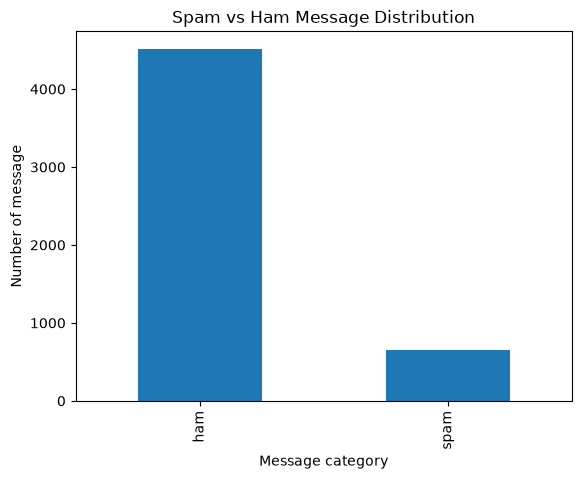

In [101]:
y.value_counts().plot(kind="bar")

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message category")
plt.ylabel("Number of message")

plt.savefig("Spam vs Ham Message Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

ADD A CONFIDENCE SCORE TO MY MODEL

In [102]:
def check_message(message):
    message_vector = loaded_vectorizer.transform([message])

    prediction = loaded_model.predict(message_vector)

    probabilities = loaded_model.predict_proba(message_vector)

    class_index = list(loaded_model.classes_).index(prediction[0])

    confidence = probabilities[0][class_index] * 100

    print("Message:", message)
    print("Prediction:", prediction[0].upper())
    print("Confidence:", round(confidence, 2), "%")

EXAMINE THE PREDICTION PROBABILITIES

In [103]:
message = ["Congratulations! You have won a free cash prize. Click here to claim it."]

message_vector = loaded_vectorizer.transform(message)

probabilities = loaded_model.predict_proba(message_vector)

for category, probability in zip(loaded_model.classes_, probabilities[0]):
    print(category, ":", round(probability * 100, 2), "%")

ham : 6.3 %
spam : 93.7 %


CHECKING MY PROBABILITIES FUNCTION TODAY

In [104]:
message = ["Congratulations! You have won a free cash prize. Click here to claim it."]

message_vector = loaded_vectorizer.transform(message)

prediction = loaded_model.predict(message_vector)

probabilities = loaded_model.predict_proba(message_vector)

print("Prediction:", prediction[0])
print("Classes:", loaded_model.classes_)
print("Probabilities:", probabilities[0])

Prediction: spam
Classes: ['ham' 'spam']
Probabilities: [0.06298032 0.93701968]


In [105]:
def check_message(message):
    message_vector = loaded_vectorizer.transform([message])

    prediction = loaded_model.predict(message_vector)

    probabilities = loaded_model.predict_proba(message_vector)

    class_index = list(loaded_model.classes_).index(prediction[0])

    confidence = probabilities[0][class_index] * 100

    print("Message:", message)
    print("Prediction:", prediction[0].upper())
    print("Confidence:", round(confidence, 2), "%")

In [107]:
check_message("You have won a free iphone claim your prize now?")

Message: You have won a free iphone claim your prize now?
Prediction: SPAM
Confidence: 92.13 %


In [106]:
check_message("URGENT! you have won a lottery ticket. click on the link below to claim your ticket now.")

Message: URGENT! you have won a lottery ticket. click on the link below to claim your ticket now.
Prediction: SPAM
Confidence: 59.46 %


In [108]:
check_message("Good MOrning! how was your night my love??")

Message: Good MOrning! how was your night my love??
Prediction: HAM
Confidence: 99.78 %


MY FINAL PROJECT VERIFICATION


In [109]:
print("Model loaded:", loaded_model is not None)
print("vectorizer loaded:", loaded_vectorizer is not None)
print ("Prediction Function available:", callable(check_message))

Model loaded: True
vectorizer loaded: True
Prediction Function available: True


ORGANIZING MY PROJECT

In [110]:
import os 

for file in os.listdir():
    print(file)

Ai_spam_detector.ipynb
app.py
classification_report.txt
README.md
requirements.txt
Sms_spam_collection.csv
Spam vs Ham Message Distribution.png
Spam_and_ham_detector_model.pkl
Spam_detection_history.csv
spam_detection_statistics.png
spam_model.pkl
tfidf_vectorizer.pkl
